<a href="https://colab.research.google.com/github/Tejendersingsethi334/Maincraft-/blob/main/Maincraft_Task2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Step 1 — Import Libraries

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Step 2 — Load Titanic Dataset

In [4]:
from google.colab import files

uploaded = files.upload()

Saving train.csv to train.csv


# Step 3 — Display First 5 Rows

In [8]:
df = pd.read_csv("train.csv")

In [9]:
df.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


# **Step 5 — Check Column Names**

In [11]:
df.columns

Index(['PassengerId', 'Survived', 'Pclass', 'Name', 'Sex', 'Age', 'SibSp',
       'Parch', 'Ticket', 'Fare', 'Cabin', 'Embarked'],
      dtype='object')

# **Step 6 — Check Data Types**

In [12]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    object 
 4   Sex          891 non-null    object 
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    object 
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    object 
 11  Embarked     889 non-null    object 
dtypes: float64(2), int64(5), object(5)
memory usage: 83.7+ KB


# Step 7 — Check Missing Values

In [13]:
df.isnull().sum()

,0
PassengerId,0
Survived,0
Pclass,0
Name,0
Sex,0
Age,177
SibSp,0
Parch,0
Ticket,0
Fare,0


# Step 8 — Handle Missing Age Values

In [14]:
df['Age'].median()

28.0

In [16]:
df['Age'] = df['Age'].fillna(df['Age'].median())

In [17]:
df['Age'].isnull().sum()

np.int64(0)

# Step 9 — Check Embarked Missing Values

In [18]:
df['Embarked'].isnull().sum()

np.int64(2)

In [19]:
df['Embarked'] = df['Embarked'].fillna(df['Embarked'].mode()[0])

# Step 10 — Check Missing Values Again

In [20]:
df.isnull().sum()


,0
PassengerId,0
Survived,0
Pclass,0
Name,0
Sex,0
Age,0
SibSp,0
Parch,0
Ticket,0
Fare,0


# Step 11 — Basic Statistical Summary

In [21]:
df.describe()

,PassengerId,Survived,Pclass,Age,SibSp,Parch,Fare
count,891.000000,891.000000,891.000000,891.000000,891.000000,891.000000,891.000000
mean,446.000000,0.383838,2.308642,29.361582,0.523008,0.381594,32.204208
std,257.353842,0.486592,0.836071,13.019697,1.102743,0.806057,49.693429
min,1.000000,0.000000,1.000000,0.420000,0.000000,0.000000,0.000000
25%,223.500000,0.000000,2.000000,22.000000,0.000000,0.000000,7.910400
50%,446.000000,0.000000,3.000000,28.000000,0.000000,0.000000,14.454200
75%,668.500000,1.000000,3.000000,35.000000,1.000000,0.000000,31.000000
max,891.000000,1.000000,3.000000,80.000000,8.000000,6.000000,512.329200


# Step 12 — Check Survival Counts

In [22]:
df['Survived'].value_counts()

,count
Survived,
0,549
1,342


# Step 13 — Survival Rate

In [23]:
df['Survived'].mean()

np.float64(0.3838383838383838)

In [24]:
df['Survived'].mean() * 100

np.float64(38.38383838383838)

# Step 14 — Survival by Gender

In [26]:
df.groupby('Sex')['Survived'].mean() * 100

,Survived
Sex,
female,74.203822
male,18.890815


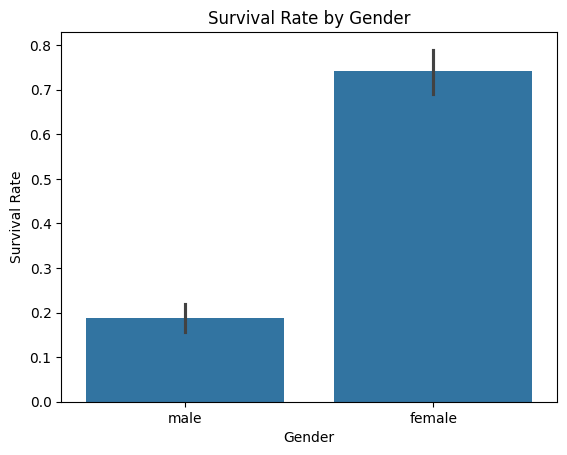

In [27]:
sns.barplot(data=df, x='Sex', y='Survived')

plt.title('Survival Rate by Gender')
plt.xlabel('Gender')
plt.ylabel('Survival Rate')

plt.show()

# Step 15 — Survival by Passenger Class

In [28]:
df.groupby('Pclass')['Survived'].mean() * 100

,Survived
Pclass,
1,62.962963
2,47.282609
3,24.236253


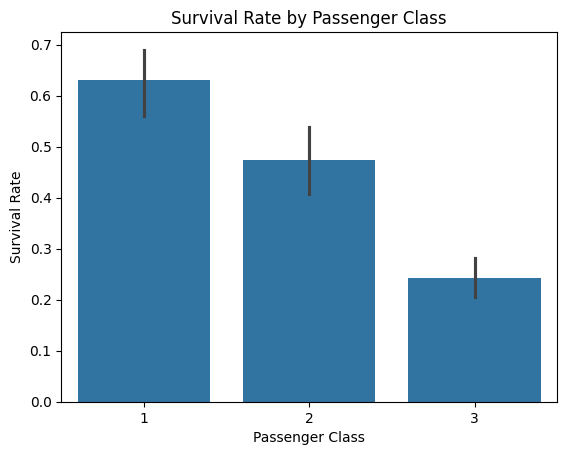

In [29]:
sns.barplot(data=df, x='Pclass', y='Survived')

plt.title('Survival Rate by Passenger Class')
plt.xlabel('Passenger Class')
plt.ylabel('Survival Rate')

plt.show()

# Step 16 — Create Age Groups

In [30]:
bins = [0, 12, 18, 35, 60, 100]

labels = ['Child', 'Teenager', 'Young Adult', 'Adult', 'Senior']

df['AgeGroup'] = pd.cut(
    df['Age'],
    bins=bins,
    labels=labels
)

# Step 17 — Survival Rate by Age Group

In [31]:
df.groupby('AgeGroup', observed=True)['Survived'].mean() * 100

,Survived
AgeGroup,
Child,57.971014
Teenager,42.857143
Young Adult,35.327103
Adult,40.000000
Senior,22.727273


# Step 18 — Age Group Visualization

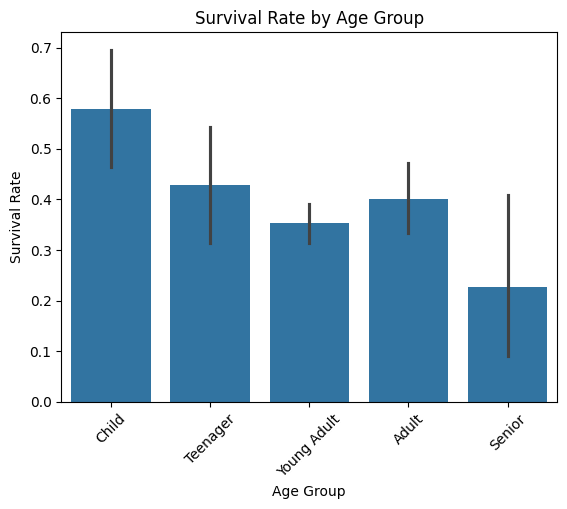

In [32]:
sns.barplot(data=df, x='AgeGroup', y='Survived')

plt.title('Survival Rate by Age Group')
plt.xlabel('Age Group')
plt.ylabel('Survival Rate')

plt.xticks(rotation=45)

plt.show()

# Step 19 — Required Histogram of Passenger Ages

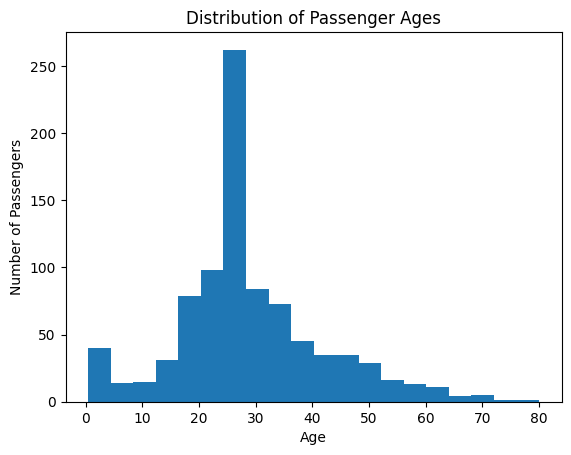

In [33]:
plt.hist(df['Age'], bins=20)

plt.title('Distribution of Passenger Ages')
plt.xlabel('Age')
plt.ylabel('Number of Passengers')

plt.show()

# Step 20 — Improve the Histogram with Seaborn

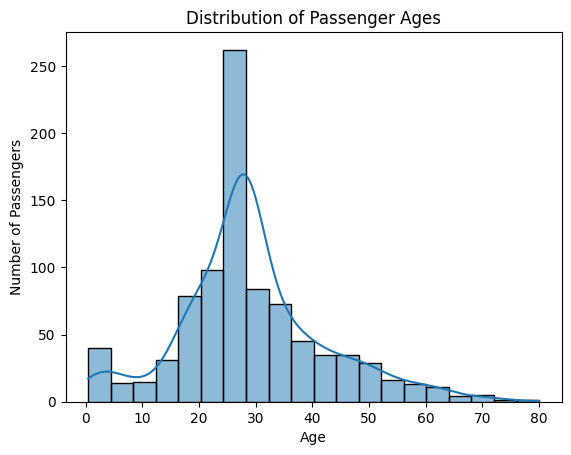

In [34]:
sns.histplot(data=df, x='Age', bins=20, kde=True)

plt.title('Distribution of Passenger Ages')
plt.xlabel('Age')
plt.ylabel('Number of Passengers')

plt.show()

# Step 21 — Final Dataset Check

In [35]:
df.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked,AgeGroup
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S,Young Adult
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C,Adult
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S,Young Adult
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S,Young Adult
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S,Young Adult


In [36]:
df.isnull().sum()

,0
PassengerId,0
Survived,0
Pclass,0
Name,0
Sex,0
Age,0
SibSp,0
Parch,0
Ticket,0
Fare,0


# Step 22 — Final Conclusions

## Conclusion

1. Female passengers had a higher survival rate than male passengers.

2. Passenger class affected survival chances. Passengers from higher classes generally had better survival rates.

3. Survival rates varied across different age groups.

4. The age histogram shows the distribution of passenger ages in the Titanic dataset.

5. Data cleaning was performed by handling missing values in important columns such as Age.